In [1]:
!pip install opencv-python

In [2]:
import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

In [7]:
#CLONE SAM2
!git clone https://github.com/facebookresearch/sam2.git

Cloning into 'sam2'...


remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 1107 (delta 10), reused 4 (delta 4), pack-reused 1093 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 29.09 MiB/s, done.
Resolving deltas: 100% (385/385), done.


In [8]:
%cd sam2

!pip install .

/home/zahranadeem/thesis/sam2


/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


Processing /home/zahranadeem/thesis/sam2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for SAM-2: filename=sam_2-1.0-py3-none-any.whl size=181433 sha256=0b1e6d28c49cda1aeb3aebf42ca0ccf03123cfbb645dadfe110357cf455502e7
  Stored in directory: /tmp/pip-ephem-wheel-cache-qfv77kcx/wheels/47/ec/7c/2d1e02d860eb3519f4d5253a45fb62e816e6be7a406e19a41a
Successfully built SAM-2


In [3]:
#Downloading weights 
import os

os.makedirs("checkpoints", exist_ok=True)

!wget -P checkpoints \
https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_small.pt


--2026-06-26 17:52:33--  https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 52.222.236.117, 52.222.236.65, 52.222.236.115, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|52.222.236.117|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184309650 (176M) [application/vnd.snesdev-page-table]
Saving to: ‘checkpoints/sam2_hiera_small.pt’

sam2_hiera_small.pt   0%[                    ]       0  --.-KB/s               

sam2_hiera_small.pt 100%[===================>] 175,77M   111MB/s    in 1,6s    

2026-06-26 17:52:34 (111 MB/s) - ‘checkpoints/sam2_hiera_small.pt’ saved [184309650/184309650]



In [4]:
import os

print(os.path.exists("checkpoints/sam2_hiera_small.pt"))

True


In [5]:
import os

os.makedirs(
    "/home/zahranadeem/thesis/sam2/checkpoints",
    exist_ok=True
)

In [6]:
import os

path = "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt"

print(os.path.exists(path))

True


In [7]:
import os
print(os.getcwd())

/home/zahranadeem


In [8]:
import os
import glob

pth_files = glob.glob(
    "/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/*.pth"
)

print("PTH files:")
for f in pth_files:
    print(f)

PTH files:
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/distutils-precedence.pth


In [9]:
for f in pth_files:
    print("\n", f)
    with open(f) as file:
        print(file.read())


 /home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/distutils-precedence.pth
import os; var = 'SETUPTOOLS_USE_DISTUTILS'; enabled = os.environ.get(var, 'stdlib') == 'local'; enabled and __import__('_distutils_hack').add_shim(); 



In [10]:
#IMPORT SAM2 
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

In [11]:
#DEVICE 
device = torch.device(

            'cuda'

            if torch.cuda.is_available()

            else 'cpu'

)

print(device)

cuda


In [12]:
!ls /home/zahranadeem/thesis/sam2/


assets		    demo		 notebooks	   sav_dataset
backend.Dockerfile  docker-compose.yaml  pyproject.toml    setup.py
build		    INSTALL.md		 README.md	   tools
checkpoints	    LICENSE		 RELEASE_NOTES.md  training
CODE_OF_CONDUCT.md  LICENSE_cctorch	 sam2
CONTRIBUTING.md     MANIFEST.in		 SAM_2.egg-info


In [13]:
#Loading SAM2 
checkpoint = "checkpoints/sam2_hiera_small.pt"

config = "sam2_hiera_s.yaml"



sam2_model = build_sam2(

                    config,

                    checkpoint,

                    device=device

)



predictor = SAM2ImagePredictor(

                    sam2_model

)

In [53]:
#LOAD VEGANN 
from datasets import load_dataset
dataset = load_dataset(
            "simonMadec/VegAnn"
)
sample = dataset['train'][0]

print(sample.keys())

sample = dataset['train'][0]

image = sample['image']
mask = sample['mask']



image = np.array(image)

mask = np.array(mask)


dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [113]:
gt_mask = mask.copy()

print(gt_mask.shape)
print(np.unique(gt_mask))
print(gt_mask.sum())

# VegAnn vegetation = 0
gt_mask = gt_mask == 0

print(np.unique(gt_mask))
print(gt_mask.sum())

print("Prediction:", pred_mask.shape)
print("Ground Truth:", gt_mask.shape)

gt_mask = mask == 0

print(np.unique(gt_mask))

(512, 512)
[  0 255]
17552415
[False  True]
193311
Prediction: (512, 512)
Ground Truth: (512, 512)
[False  True]


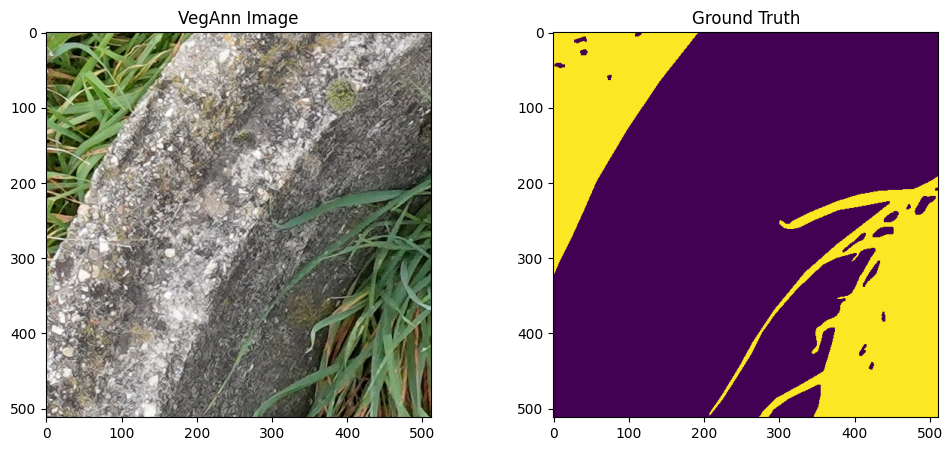

In [114]:
plt.figure(figsize=(12,5))


plt.subplot(121)

plt.imshow(image)

plt.title("VegAnn Image")



plt.subplot(122)

plt.imshow(mask)

plt.title("Ground Truth")


plt.show()

In [115]:
#Sending Image to SAM2 
predictor.set_image(

            image

)

In [116]:
#Baseline/center point prompt (assuning all the plants are in the center of the image,
# i.e. not true for VegAnn)

"""H,W = image.shape[:2]


point = np.array([

                [

                W//2,

                H//2

                ]

])



label = np.array(

                [1]

)"""

#Using Oracle Prompts -> 
# Since VegAnn provides GT masks, we can use the GT centroid as the prompt. 
# This gives the upper bound performance of SAM2.
"""ys, xs = np.where(mask > 0)

cx = int(xs.mean())
cy = int(ys.mean())

point = np.array([[cx, cy]])
label = np.array([1])

print(point)"""


'ys, xs = np.where(mask > 0)\n\ncx = int(xs.mean())\ncy = int(ys.mean())\n\npoint = np.array([[cx, cy]])\nlabel = np.array([1])\n\nprint(point)'

In [ ]:
#Creating Bounding box 
ys, xs = np.where(mask > 0)

box = np.array([
    xs.min(),
    ys.min(),
    xs.max(),
    ys.max()
])

print(box)

[  0   0 511 511]


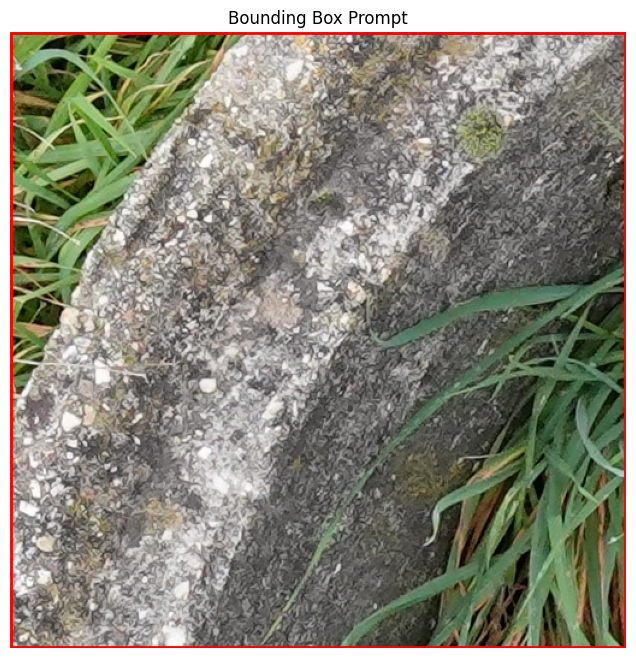

In [139]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

x1, y1, x2, y2 = box

fig, ax = plt.subplots(figsize=(8,8))

ax.imshow(image)

rect = patches.Rectangle(
    (x1, y1),             # top-left corner
    x2 - x1,              # width
    y2 - y1,              # height
    linewidth=2,
    edgecolor='red',
    facecolor='none'
)

ax.add_patch(rect)

plt.title("Bounding Box Prompt")
plt.axis('off')
plt.show()

In [118]:
#Predicting mask
"""masks, scores, logits = predictor.predict(

                    point_coords=point,

                    point_labels=label,

                    multimask_output=True

)"""
predictor.set_image(image)

masks, scores, logits = predictor.predict(
    box=box,
    multimask_output=True
)

best_mask = masks[scores.argmax()]


In [119]:
print("Masks shape:")
print(masks.shape)

print()

print("Scores:")
print(scores)

print()

print("Logits shape:")
print(logits.shape)

Masks shape:
(3, 512, 512)

Scores:
[0.8116866 0.9585552 0.7774918]

Logits shape:
(3, 256, 256)


In [120]:
print(pred_mask.sum())

100748


In [121]:
best_idx = scores.argmax()

pred_mask = masks[best_idx]

print("Best score:")
print(scores[best_idx])

print()

print("Mask pixels:")
print(pred_mask.sum())

Best score:
0.9585552

Mask pixels:
167670.0


In [122]:
print("GT shape:")
print(gt_mask.shape)

print()

print("GT pixels:")
print(gt_mask.sum())

print()

print("Unique values:")
print(np.unique(gt_mask))

GT shape:
(512, 512)

GT pixels:
193311

Unique values:
[False  True]


In [123]:
#Seletcing best mask 
best_mask = masks[0]
#np.argmax(scores)

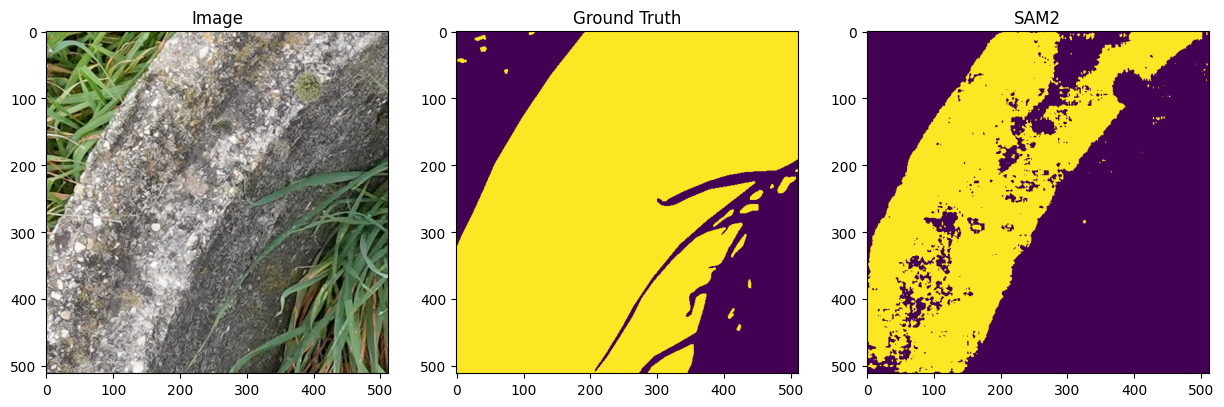

In [126]:
plt.figure(figsize=(15,5))


plt.subplot(131)

plt.imshow(image)

plt.title("Image")



plt.subplot(132)

plt.imshow(gt_mask)

plt.title("Ground Truth")



plt.subplot(133)

plt.imshow(best_mask)

plt.title("SAM2")


plt.show()

In [127]:
pred_mask = best_mask > 0

In [131]:
# Select best SAM2 mask
best_idx = np.argmax(scores)
best_mask = masks[best_idx]

# Convert prediction to binary
pred_mask = best_mask > 0

# VegAnn foreground/vegetation is encoded as 0
gt_mask = mask == 0

print("Prediction:", pred_mask.shape)
print("Ground Truth:", gt_mask.shape)

print("Pred pixels:", pred_mask.sum())
print("GT pixels:", gt_mask.sum())

print("GT unique original values:", np.unique(mask))
print("GT unique binary values:", np.unique(gt_mask))

# Calculate IoU and Dice
intersection = np.logical_and(pred_mask, gt_mask).sum()
union = np.logical_or(pred_mask, gt_mask).sum()

iou = intersection / union

dice = (2 * intersection) / (pred_mask.sum() + gt_mask.sum())

print("Intersection:", intersection)
print("IoU:", iou)
print("Dice:", dice)

Prediction: (512, 512)
Ground Truth: (512, 512)
Pred pixels: 167670
GT pixels: 193311
GT unique original values: [  0 255]
GT unique binary values: [False  True]
Intersection: 167648
IoU: 0.8671463226660736
Dice: 0.9288466706003917


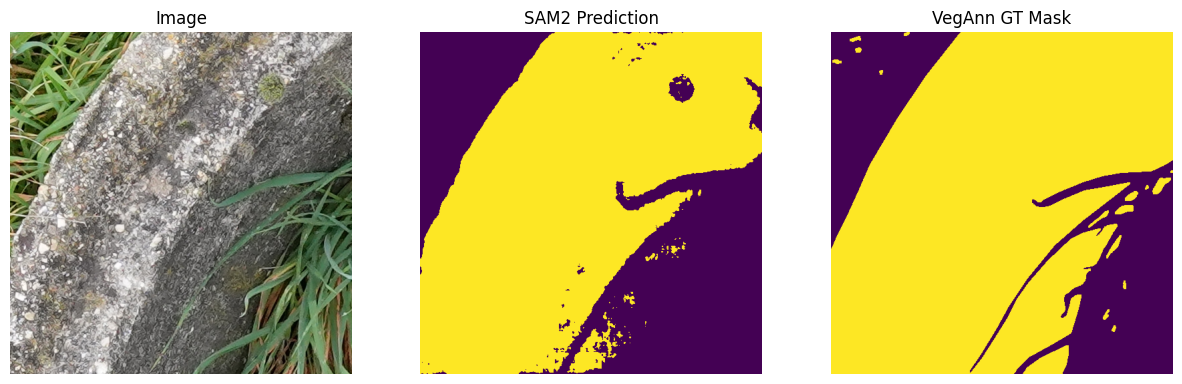

In [129]:
plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(pred_mask)
plt.title("SAM2 Prediction")
plt.axis("off")

plt.subplot(133)
plt.imshow(gt_mask)
plt.title("VegAnn GT Mask")
plt.axis("off")

plt.show()

In [130]:
gt_mask = mask > 0
pred_mask = best_mask > 0

print("Pred pixels:", pred_mask.sum())
print("GT pixels:", gt_mask.sum())

intersection = np.logical_and(pred_mask, gt_mask)

print("Intersection pixels:", intersection.sum())

Pred pixels: 167670
GT pixels: 68833
Intersection pixels: 22


In [134]:
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "SAM2 + Point Prompt",
        "SAM2 + Box Prompt"
    ],
    "IoU": [
        0.5211705490116961,
        0.8671463226660736
    ],
    "Dice": [
        0.6852230334728745,
        0.9288466706003917
    ]
})

print(results)

                Method       IoU      Dice
0  SAM2 + Point Prompt  0.521171  0.685223
1    SAM2 + Box Prompt  0.867146  0.928847


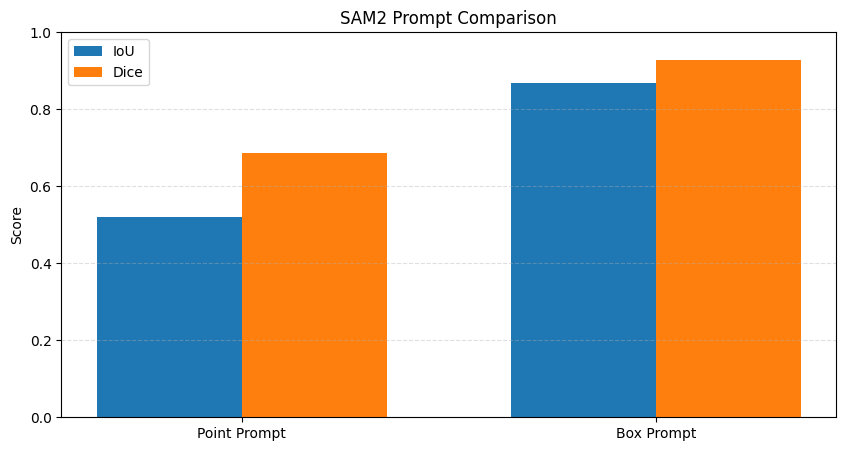

In [135]:
import matplotlib.pyplot as plt
import numpy as np

methods = ["Point Prompt", "Box Prompt"]

iou_scores = [0.5211705490116961, 0.8671463226660736]
dice_scores = [0.6852230334728745, 0.9288466706003917]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(10,5))

plt.bar(x - width/2, iou_scores, width, label='IoU')
plt.bar(x + width/2, dice_scores, width, label='Dice')

plt.xticks(x, methods)
plt.ylabel("Score")
plt.title("SAM2 Prompt Comparison")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()

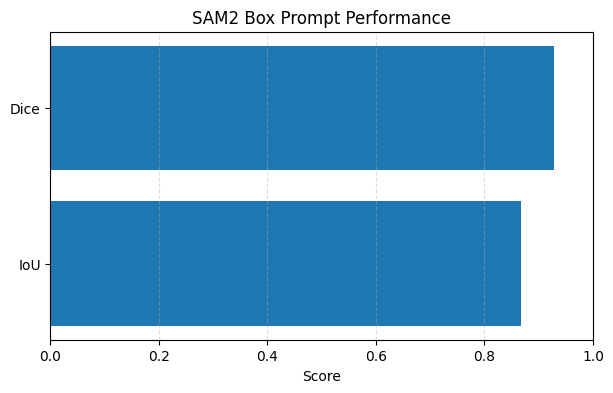

In [136]:
import matplotlib.pyplot as plt

metrics = ["IoU", "Dice"]
scores = [0.8671463226660736, 0.9288466706003917]

plt.figure(figsize=(7,4))

plt.barh(metrics, scores)

plt.title("SAM2 Box Prompt Performance")
plt.xlim(0,1)
plt.xlabel("Score")
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.show()

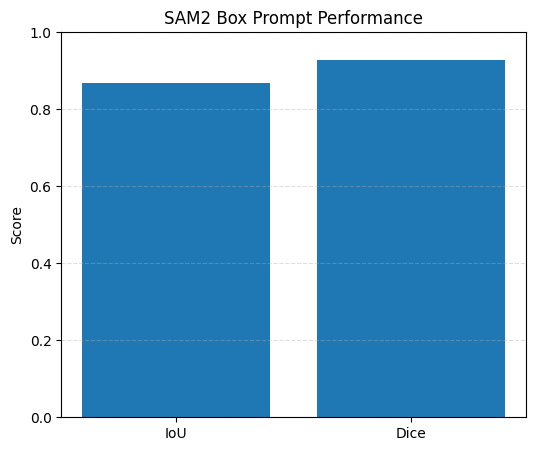

In [137]:
import matplotlib.pyplot as plt

metrics = ["IoU", "Dice"]
scores = [0.8671463226660736, 0.9288466706003917]

plt.figure(figsize=(6,5))

plt.bar(metrics, scores)

plt.title("SAM2 Box Prompt Performance")
plt.ylabel("Score")
plt.ylim(0,1)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()